# 1. Portada e introducción

**Equipo:** 21  
**Curso:** Modelos Avanzados de Procesamiento de Lenguaje Natural  
**Actividad:** Micro proyecto 3 — Generación condicional de código con LLMs

## Objetivo
Generar soluciones Python a partir de descripciones de MBPP y comparar la correctitud funcional de dos modelos originales con sus versiones ajustadas mediante LoRA.

| Familia | Modelo original | Modelo ajustado |
|---|---|---|
| Qwen | `Qwen/Qwen2.5-1.5B` | Mismos pesos base con LoRA |
| SmolLM2 | `HuggingFaceTB/SmolLM2-1.7B` | Mismos pesos base con LoRA |

Se emplea MBPP `full`, con 374 ejemplos de entrenamiento, 90 de validación y 500 de prueba. La métrica principal es pass@1: proporción de problemas cuyas soluciones pasan todos los asserts asociados. Los resultados conservados corresponden a la ejecución de estos modelos base, no a variantes Instruct.

Se utilizó asistencia de IA en la preparación y revisión del notebook. La validación de las decisiones, la interpretación y el cumplimiento de las reglas del curso corresponden al equipo.

# 2. Librerías

## Entorno reproducible
Se fijan las versiones del ecosistema Hugging Face para reducir cambios de API entre sesiones. Se conserva PyTorch con CUDA instalado por Colab. Se retiran paquetes opcionales de cuantización, audio y visión que no se usan aquí y que pueden provocar conflictos al importar librerías de texto. La retirada de `torchao` sigue el enfoque del tutorial GPT adjunto; no necesitamos cuantización para estos modelos en una GPU de aproximadamente 16 GB.


In [ ]:
import sys
import subprocess
import importlib.metadata as metadata

PINNED = {
    "transformers": "4.57.3",
    "peft": "0.18.0",
    "datasets": "4.4.1",
    "accelerate": "1.12.0",
}

for package, expected in PINNED.items():
    if package in sys.modules:
        installed = metadata.version(package)
        if installed != expected:
            raise RuntimeError(
                f"{package} ya está importado con versión {installed}. "
                "Abre una sesión nueva antes de instalar las dependencias."
            )

subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y",
     "torchao", "torchvision", "torchaudio", "librosa"],
    check=True
)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q"]
    + [f"{name}=={version}" for name, version in PINNED.items()]
    + ["sentencepiece", "pandas", "matplotlib"],
    check=True
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.57.3', 'peft==0.18.0', 'datasets==4.4.1', 'accelerate==1.12.0', 'sentencepiece', 'pandas', 'matplotlib'], returncode=0)

In [ ]:
import ast
import contextlib
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import signal
import tempfile
import time
from pathlib import Path
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
import datasets
import peft
import accelerate
from IPython.display import display, Markdown
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import (
    AutoModelForCausalLM, AutoTokenizer, GenerationConfig,
    get_linear_schedule_with_warmup, set_seed,
)
from peft import LoraConfig, PeftModel, get_peft_model
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

assert torch.cuda.is_available(), "Activa una GPU antes de continuar."
assert platform.system() == "Linux", "El evaluador requiere Linux, como Google Colab."

SEED = 42
set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False

VERSIONS = {
    name: metadata.version(name)
    for name in ["torch", *PINNED, "numpy", "pandas", "matplotlib"]
}
print(json.dumps(VERSIONS, indent=2))
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM total (GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

{
  "torch": "2.14.1+cu130",
  "transformers": "4.57.3",
  "peft": "0.18.0",
  "datasets": "4.4.1",
  "accelerate": "1.12.0",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0"
}
GPU: Tesla T4
VRAM total (GB): 14.56


## Configuración central
La tasa de aprendizaje es `1e-4`, con un máximo de cinco épocas y selección por la menor pérdida de validación. Se aplica parada temprana tras dos épocas sin mejora. La configuración es común a ambas familias y no se modifica a partir de los resultados del test.

LoRA utiliza rango 16, alpha 16, dropout 0.05 y las proyecciones de atención `q/k/v/o`. Un microbatch de un ejemplo y acumulación de ocho reduce la presión de memoria. Se emplean FP16, escalado y recorte de gradientes, y gradient checkpointing.

La evaluación usa los 500 problemas, una respuesta greedy, un máximo de 384 tokens nuevos y EOS como parada, con el mismo procesamiento en las cuatro configuraciones. Los archivos se calculan localmente y se copian a Drive en los hitos descritos al inicio.


In [ ]:
MODELS = {
    "qwen": "Qwen/Qwen2.5-1.5B",
    "smollm": "HuggingFaceTB/SmolLM2-1.7B",
}
assert all(not model_id.endswith("-Instruct") for model_id in MODELS.values())

ROOT = LOCAL_ROOT
ROOT.mkdir(exist_ok=True)

CONFIG = {
    "seed": SEED,
    "prompt_version": "mbpp_plain_english_interface_v1",
    "models": MODELS,
    "training": {
        "learning_rate": 1e-4,
        "max_epochs": 5,
        "patience": 2,
        "microbatch": 1,
        "accumulation_steps": 8,
        "weight_decay": 0.01,
        "warmup_ratio": 0.10,
        "max_grad_norm": 1.0,
        "lora_r": 16,
        "lora_alpha": 16,
        "lora_dropout": 0.05,
        "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj"],
    },
    "generation": {
        "do_sample": False,
        "num_beams": 1,
        "max_new_tokens": 384,
        "initial_batch_size": 8,
        "stop": "tokenizer.eos_token_id",
    },
    "evaluation": {
        "test_problems": 500,
        "timeout_seconds": 5,
        "memory_mb": 1024,
        "code_extraction": "first_python_fence_else_raw_v1",
    },
}


def digest(value):
    content = json.dumps(value, sort_keys=True, ensure_ascii=False).encode()
    return hashlib.sha256(content).hexdigest()


def save_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(data, indent=2, ensure_ascii=False, allow_nan=False),
        encoding="utf-8"
    )
    temporary.replace(path)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


config_path = ROOT / "config.json"
if config_path.exists():
    assert read_json(config_path) == CONFIG, (
        "La carpeta contiene otra configuración. Usa una carpeta ROOT nueva."
    )
save_json(config_path, CONFIG)
save_json(ROOT / "versions.json", VERSIONS)
(ROOT / "requirements.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in VERSIONS.items()) + "\n",
    encoding="utf-8"
)
print("Carpeta de trabajo:", ROOT.resolve())
backup_to_drive("configuracion")

Carpeta de trabajo: /content/microproyecto3_modelos_base_v1
Mounted at /content/drive
Respaldo en Drive: 3 archivos | Modelos_Avanzados_PLN/Microproyecto_3/respaldos/configuracion.zip


PosixPath('/content/drive/MyDrive/Modelos_Avanzados_PLN/Microproyecto_3/respaldos/configuracion.zip')

# 3. Carga del dataset y exploración

MBPP, configuración `full`, contiene descripción (`text`), solución de referencia (`code`), asserts (`test_list`), preparación (`test_setup_code`) y pruebas adicionales (`challenge_test_list`). La métrica principal utiliza todos los asserts de `test_list`; no mezcla los tests adicionales con el protocolo principal.

Se fija la revisión descargada y se guardan las huellas de los datos. La exploración se limita a entrenamiento; no se inspeccionaron soluciones de test para elegir prompts o hiperparámetros.

In [ ]:
api = HfApi()
revision_path = ROOT / "revisions.json"
if revision_path.exists():
    REVISIONS = read_json(revision_path)
else:
    REVISIONS = {
        "dataset": api.dataset_info("google-research-datasets/mbpp").sha,
        "models": {
            key: api.model_info(model_id).sha
            for key, model_id in MODELS.items()
        }
    }
    save_json(revision_path, REVISIONS)

dataset = load_dataset(
    "google-research-datasets/mbpp", "full",
    revision=REVISIONS["dataset"]
)
assert {key: len(dataset[key]) for key in dataset} == {
    "train": 374, "test": 500, "validation": 90, "prompt": 10
}
DATA_FINGERPRINT = digest({
    split: dataset[split].to_list() for split in dataset
})
save_json(ROOT / "dataset_manifest.json", {
    "repository": "google-research-datasets/mbpp",
    "configuration": "full",
    "revision": REVISIONS["dataset"],
    "fingerprint": DATA_FINGERPRINT,
    "sizes": {split: len(dataset[split]) for split in dataset},
})
display(pd.DataFrame([
    {"Partición": split, "Ejemplos": len(dataset[split])}
    for split in dataset
]))

for example in dataset["train"].select(range(2)):
    print("=" * 70)
    print("task_id:", example["task_id"])
    print("Instrucción:", example["text"])
    print("\nReferencia:\n" + example["code"])
    print("Preparación:", repr(example["test_setup_code"]))
    print("Asserts:")
    print("\n".join(example["test_list"]))

README.md: 0.00B [00:00, ?B/s]

full/train-00000-of-00001.parquet:   0%|          | 0.00/87.2k [00:00<?, ?B/s]

full/test-00000-of-00001.parquet:   0%|          | 0.00/116k [00:00<?, ?B/s]

full/validation-00000-of-00001.parquet:   0%|          | 0.00/25.1k [00:00<?, ?B/s]

full/prompt-00000-of-00001.parquet:   0%|          | 0.00/7.88k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/374 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/90 [00:00<?, ? examples/s]

Generating prompt split:   0%|          | 0/10 [00:00<?, ? examples/s]

,Partición,Ejemplos
0,train,374
1,test,500
2,validation,90
3,prompt,10


task_id: 601
Instrucción: Write a function to find the longest chain which can be formed from the given set of pairs.

Referencia:
class Pair(object): 
	def __init__(self, a, b): 
		self.a = a 
		self.b = b 
def max_chain_length(arr, n): 
	max = 0
	mcl = [1 for i in range(n)] 
	for i in range(1, n): 
		for j in range(0, i): 
			if (arr[i].a > arr[j].b and
				mcl[i] < mcl[j] + 1): 
				mcl[i] = mcl[j] + 1
	for i in range(n): 
		if (max < mcl[i]): 
			max = mcl[i] 
	return max
Preparación: ''
Asserts:
assert max_chain_length([Pair(5, 24), Pair(15, 25),Pair(27, 40), Pair(50, 60)], 4) == 3
assert max_chain_length([Pair(1, 2), Pair(3, 4),Pair(5, 6), Pair(7, 8)], 4) == 4
assert max_chain_length([Pair(19, 10), Pair(11, 12),Pair(13, 14), Pair(15, 16), Pair(31, 54)], 5) == 5
task_id: 602
Instrucción: Write a python function to find the first repeated character in a given string.

Referencia:
def first_repeated_char(str1):
  for index,c in enumerate(str1):
    if str1[:index+1].count(c) > 1:
  

# 4. Construcción de prompts y preprocesamiento

## Un único formato para ambas familias
Los modelos base son completadores de texto. No se usaron roles de chat ni `apply_chat_template`. La instrucción se escribe en inglés porque las descripciones de MBPP ya están en inglés; no se tradujeron ni modificaron los problemas.

Cada entrada incluye la descripción y la interfaz de llamada esperada (nombre y parámetros de la función). Esta interfaz se extrae automáticamente del encabezado de la referencia, sin incluir su cuerpo, imports, solución ni valores de los asserts. Es metadato de la tarea, no un ejemplo resuelto ni few-shot. Se declara esta decisión para que el protocolo sea explícito: el resultado mide generación condicionada a descripción e interfaz, no inferencia del nombre de la función. Los asserts se consultan únicamente para identificar cuál de las funciones de la referencia es el punto de entrada, sin mostrarlos al modelo.

La tokenización concatena los tokens del prompt con los tokens de la solución y EOS. Se verifica que no aparezcan tokens del prompt en la pérdida: esos labels son `-100`. No se usa un número fijo de posiciones para comprobar la máscara. Se conservan todas las soluciones, sin filtrar ni truncar ejemplos; se informa la longitud máxima antes de entrenar.

In [ ]:
def public_signature(example):
    tree = ast.parse(example["code"])
    functions = [
        node for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    ]
    if not functions:
        raise ValueError(f"No se encontró función en task_id={example['task_id']}")
    called_names = []
    for test in example["test_list"]:
        for node in ast.walk(ast.parse(test)):
            if isinstance(node, ast.Call) and isinstance(node.func, ast.Name):
                called_names.append(node.func.id)
    candidates = {node.name: node for node in functions}
    name = next((name for name in called_names if name in candidates), functions[-1].name)
    node = candidates[name]
    args = ast.arguments(
        posonlyargs=[ast.arg(arg=a.arg) for a in node.args.posonlyargs],
        args=[ast.arg(arg=a.arg) for a in node.args.args],
        vararg=ast.arg(arg=node.args.vararg.arg) if node.args.vararg else None,
        kwonlyargs=[ast.arg(arg=a.arg) for a in node.args.kwonlyargs],
        kw_defaults=[None] * len(node.args.kwonlyargs),
        kwarg=ast.arg(arg=node.args.kwarg.arg) if node.args.kwarg else None,
        defaults=[],
    )
    return f"def {name}({ast.unparse(args)}):"


def build_prompt(example):
    return (
        "Write a Python solution for the following programming problem.\n"
        "Return only valid Python code, including any necessary imports or helper definitions.\n"
        "Use the required function name and parameters. Do not add examples or explanations.\n\n"
        f"### Problem\n{example['text'].strip()}\n\n"
        f"### Required interface\n{public_signature(example)}\n\n"
        "### Python solution\n"
    )


def load_tokenizer(key):
    tokenizer = AutoTokenizer.from_pretrained(
        MODELS[key], revision=REVISIONS["models"][key]
    )
    assert tokenizer.eos_token_id is not None
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"
    return tokenizer


def encode_training_example(example, tokenizer):
    prompt_ids = tokenizer.encode(build_prompt(example), add_special_tokens=False)
    solution_ids = tokenizer.encode(example["code"].strip(), add_special_tokens=False)
    target_ids = solution_ids + [tokenizer.eos_token_id]
    input_ids = prompt_ids + target_ids
    labels = [-100] * len(prompt_ids) + target_ids
    assert len(input_ids) == len(labels)
    assert all(x == -100 for x in labels[:len(prompt_ids)])
    assert labels[len(prompt_ids):] == target_ids
    assert len(target_ids) > 1
    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels,
    }


def tokenize_training_split(split, tokenizer):
    return [encode_training_example(example, tokenizer) for example in split]


print(build_prompt(dataset["train"][0]))
TOKENIZATION_REPORT = []
for key in MODELS:
    tokenizer = load_tokenizer(key)
    for split_name in ["train", "validation"]:
        encoded = tokenize_training_split(dataset[split_name], tokenizer)
        lengths = [len(row["input_ids"]) for row in encoded]
        TOKENIZATION_REPORT.append({
            "Modelo": key, "Partición": split_name,
            "Ejemplos": len(encoded), "Tokens máximos": max(lengths),
            "Tokens promedio": float(np.mean(lengths)),
            "Truncados": 0,
        })
    example = encode_training_example(dataset["train"][0], tokenizer)
    visible = [token for token in example["labels"] if token != -100]
    print("\nObjetivo de entrenamiento:", key)
    print(tokenizer.decode(visible, skip_special_tokens=False))
    del tokenizer, encoded, example

tokenization_df = pd.DataFrame(TOKENIZATION_REPORT)
display(tokenization_df)
tokenization_df.to_csv(ROOT / "tokenization_report.csv", index=False)

Write a Python solution for the following programming problem.
Return only valid Python code, including any necessary imports or helper definitions.
Use the required function name and parameters. Do not add examples or explanations.

### Problem
Write a function to find the longest chain which can be formed from the given set of pairs.

### Required interface
def max_chain_length(arr, n):

### Python solution



tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

<unknown>:3: SyntaxWarning: invalid escape sequence '\B'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:15: SyntaxWarning: invalid escape sequence '\s'
<unknown>:4: SyntaxWarning: invalid escape sequence '\A'
<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:3: SyntaxWarning: invalid escape sequence '\.'


... (6 outputs left out)

<unknown>:3: SyntaxWarning: invalid escape sequence '\B'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:15: SyntaxWarning: invalid escape sequence '\s'
<unknown>:4: SyntaxWarning: invalid escape sequence '\A'
<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'



Objetivo de entrenamiento: smollm
class Pair(object): 
	def __init__(self, a, b): 
		self.a = a 
		self.b = b 
def max_chain_length(arr, n): 
	max = 0
	mcl = [1 for i in range(n)] 
	for i in range(1, n): 
		for j in range(0, i): 
			if (arr[i].a > arr[j].b and
				mcl[i] < mcl[j] + 1): 
				mcl[i] = mcl[j] + 1
	for i in range(n): 
		if (max < mcl[i]): 
			max = mcl[i] 
	return max<|endoftext|>


<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:3: SyntaxWarning: invalid escape sequence '\.'


,Modelo,Partición,Ejemplos,Tokens máximos,Tokens promedio,Truncados
0,qwen,train,374,361,131.620321,0
1,qwen,validation,90,276,133.366667,0
2,smollm,train,374,389,150.433155,0
3,smollm,validation,90,324,153.200000,0


# 5. Particiones (train / validation / test)

- `train`: los 374 problemas se usan para actualizar los adaptadores.
- `validation`: los 90 problemas se usan para medir la pérdida después de cada época y elegir el checkpoint. No actualizan los pesos.
- `test`: los 500 problemas se usan en las cuatro evaluaciones finales de pass@1. No se utilizan para cambiar la configuración, seleccionar épocas ni probar prompts.
- `prompt`: los 10 ejemplos no se utilizan. No se incorporan demostraciones, para mantener el escenario zero-shot.

Se comprueba la separación por `task_id`. Esto no garantiza que no haya contaminación en el preentrenamiento de los modelos; ese aspecto no puede verificarse con este experimento.

In [ ]:
train_split = dataset["train"]
validation_split = dataset["validation"]
test_split = dataset["test"]

split_ids = {
    name: set(dataset[name]["task_id"])
    for name in ["train", "validation", "test", "prompt"]
}
for left, left_ids in split_ids.items():
    for right, right_ids in split_ids.items():
        if left != right:
            assert left_ids.isdisjoint(right_ids), f"Solapamiento: {left}, {right}"

assert len(test_split) == CONFIG["evaluation"]["test_problems"]
print("Particiones disjuntas. Test reservado para las cuatro evaluaciones finales.")

Particiones disjuntas. Test reservado para las cuatro evaluaciones finales.


# 6. Implementación de la evaluación pass@1

## Protocolo funcional y límites
Para cada problema se genera una sola respuesta (`do_sample=False`, `num_beams=1`). Se aplica padding a la izquierda, se entrega `attention_mask` y se recorta la anchura completa del prompt antes de decodificar. No se usa muestreo, búsqueda de varias soluciones ni reparación posterior.

El único posprocesamiento retira un primer bloque Markdown de código, si existe. No cambia nombres de funciones, no corta al encontrar `print`, no añade imports y no corrige errores. Se conservan tanto la respuesta original como el código evaluado. Un código sintácticamente incorrecto cuenta como fallo.

Cada solución debe pasar todos los asserts de `test_list`, después de ejecutar `test_setup_code`. Se ejecuta en un proceso Python nuevo, en un directorio temporal, con entorno reducido, límite de CPU, memoria, tamaño de archivos y cinco segundos de pared. Los timeouts y los errores se cuentan como fallos, nunca se excluyen del denominador.

**Seguridad:** el aislamiento es de procesos y recursos, no una máquina virtual ni un sandbox hermético. No protege por completo el sistema de archivos ni la red frente a código malicioso. Durante los tests se utiliza un runtime dedicado con Drive desmontado, sin secretos ni archivos personales. No ejecutes estas soluciones en tu equipo principal. El evaluador no concede permisos adicionales.

La evaluación guarda localmente un manifiesto y las respuestas tras cada lote; los hitos completos se respaldan en Drive. Si se interrumpe una ejecución, la siguiente llamada reutiliza únicamente los registros compatibles. Un cambio de configuración o checkpoint invalida la reutilización.

In [ ]:
RUNNER_SOURCE = r"""
import contextlib
import json
import os
import resource
import sys
import traceback

payload = json.loads(sys.stdin.read())
seconds = int(payload["timeout"])
resource.setrlimit(resource.RLIMIT_CPU, (seconds, seconds + 1))
memory = int(payload["memory_mb"]) * 1024 * 1024
resource.setrlimit(resource.RLIMIT_AS, (memory, memory))
resource.setrlimit(resource.RLIMIT_FSIZE, (1024 * 1024, 1024 * 1024))
resource.setrlimit(resource.RLIMIT_CORE, (0, 0))
namespace = {"__name__": "__generated__"}
try:
    compile(payload["code"], "<generated>", "exec")
except (SyntaxError, ValueError, TypeError) as exc:
    result = {"passed": False, "status": "syntax_error", "error": str(exc)[:500]}
else:
    try:
        with open(os.devnull, "w") as sink:
            with contextlib.redirect_stdout(sink), contextlib.redirect_stderr(sink):
                exec(payload["setup"] or "", namespace)
                exec(payload["code"], namespace)
                for assertion in payload["tests"]:
                    exec(assertion, namespace)
        result = {"passed": True, "status": "passed", "error": ""}
    except AssertionError as exc:
        result = {"passed": False, "status": "assertion_error", "error": str(exc)[:500]}
    except BaseException as exc:
        result = {"passed": False, "status": "execution_error", "error": type(exc).__name__ + ": " + str(exc)[:500]}
print(json.dumps(result))
"""


def check_solution(code, tests, setup="", timeout=None):
    unmount_project_drive()
    timeout = timeout or CONFIG["evaluation"]["timeout_seconds"]
    payload = {
        "code": code, "tests": list(tests), "setup": setup or "",
        "timeout": timeout,
        "memory_mb": CONFIG["evaluation"]["memory_mb"],
    }
    environment = {
        "PATH": os.environ.get("PATH", ""),
        "LANG": "C.UTF-8", "PYTHONHASHSEED": str(SEED),
        "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1",
    }
    with tempfile.TemporaryDirectory() as working_dir:
        process = subprocess.Popen(
            [sys.executable, "-I", "-c", RUNNER_SOURCE],
            stdin=subprocess.PIPE, stdout=subprocess.PIPE,
            stderr=subprocess.DEVNULL, cwd=working_dir,
            env=environment, start_new_session=True, text=True,
        )
        try:
            stdout, _ = process.communicate(json.dumps(payload), timeout=timeout)
        except subprocess.TimeoutExpired:
            with contextlib.suppress(ProcessLookupError):
                os.killpg(process.pid, signal.SIGKILL)
            process.communicate()
            return {"passed": False, "status": "timeout", "error": "Wall-clock timeout"}
        finally:
            with contextlib.suppress(ProcessLookupError):
                os.killpg(process.pid, signal.SIGKILL)

    if process.returncode != 0:
        return {
            "passed": False, "status": "process_error",
            "error": f"returncode={process.returncode}",
        }
    try:
        result = json.loads(stdout.strip())
        assert isinstance(result["passed"], bool)
        return result
    except (ValueError, KeyError, TypeError, AssertionError):
        return {"passed": False, "status": "runner_error", "error": "Invalid runner response"}


def extract_code(text):
    text = text.strip()
    match = re.search(r"```(?:python|py)?[ \t]*\n(.*?)(?:```|$)", text, flags=re.S | re.I)
    return match.group(1).strip() if match else text


assert check_solution("def f(x):\n    return x + 1", ["assert f(2) == 3"])["passed"]
assert not check_solution("def f(x):\n    return x", ["assert f(2) == 3"])["passed"]
assert check_solution("while True:\n    pass", [], timeout=1)["status"] in {"timeout", "process_error"}
assert check_solution("def f(:", [])["status"] == "syntax_error"
assert not check_solution("raise SystemExit(0)", ["assert False"])["passed"]
assert extract_code("```python\ndef f():\n    return 1\n```\nExplanation") == "def f():\n    return 1"

for example in train_split.select(range(3)):
    result = check_solution(example["code"], example["test_list"], example["test_setup_code"])
    assert result["passed"], (example["task_id"], result)
print("Evaluador verificado con aciertos, fallos, sintaxis, timeout y referencias de train.")

Evaluador verificado con aciertos, fallos, sintaxis, timeout y referencias de train.


In [ ]:
def clear_cuda():
    gc.collect()
    torch.cuda.empty_cache()
    print(f"VRAM asignada: {torch.cuda.memory_allocated() / 2**30:.2f} GB", flush=True)


def load_base(key):
    clear_cuda()
    set_seed(SEED)
    model = AutoModelForCausalLM.from_pretrained(
        MODELS[key], revision=REVISIONS["models"][key],
        torch_dtype=torch.float16, device_map={"": 0},
        attn_implementation="sdpa",
    )
    assert model.config.model_type in {"qwen2", "llama"}
    return model


def file_sha256(path):
    hasher = hashlib.sha256()
    with Path(path).open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


def checkpoint_identity(adapter_dir):
    adapter_dir = Path(adapter_dir)
    files = sorted(adapter_dir.glob("adapter_model.*"))
    assert files, "Faltan pesos del adaptador."
    return digest({file.name: file_sha256(file) for file in files})


@torch.inference_mode()
def generate_batch(model, tokenizer, examples):
    tokenizer.padding_side = "left"
    prompts = [build_prompt(example) for example in examples]
    inputs = tokenizer(
        prompts, padding=True, truncation=False,
        add_special_tokens=False, return_tensors="pt"
    ).to("cuda")
    context_limit = getattr(model.config, "max_position_embeddings", 2048)
    assert inputs["input_ids"].shape[1] + CONFIG["generation"]["max_new_tokens"] <= context_limit
    generation_config = GenerationConfig(
        do_sample=False, num_beams=1,
        max_new_tokens=CONFIG["generation"]["max_new_tokens"],
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        bos_token_id=tokenizer.bos_token_id,
        use_cache=True,
    )
    model.eval()
    outputs = model.generate(**inputs, generation_config=generation_config)
    suffixes = outputs[:, inputs["input_ids"].shape[1]:]
    records = []
    for example, tokens in zip(examples, suffixes):
        ids = tokens.tolist()
        if tokenizer.eos_token_id in ids:
            ids = ids[:ids.index(tokenizer.eos_token_id)]
            stopped_with_eos = True
        else:
            stopped_with_eos = False
        raw = tokenizer.decode(ids, skip_special_tokens=True)
        records.append({
            "task_id": int(example["task_id"]),
            "problem": example["text"],
            "interface": public_signature(example),
            "raw_solution": raw,
            "generated_code": extract_code(raw),
            "generated_tokens": len(ids),
            "reached_token_limit": not stopped_with_eos and len(ids) >= generation_config.max_new_tokens,
        })
    return records


def evaluation_manifest(key, variant, adapter_dir=None):
    return {
        "model_id": MODELS[key], "revision": REVISIONS["models"][key],
        "variant": variant, "dataset": DATA_FINGERPRINT,
        "config_hash": digest(CONFIG),
        "prompt_hash": digest([build_prompt(example) for example in test_split]),
        "adapter_hash": checkpoint_identity(adapter_dir) if adapter_dir else None,
        "versions": VERSIONS,
    }


def evaluate_configuration(key, variant, adapter_dir=None):
    assert variant in {"zero_shot", "lora"}
    assert (variant == "lora") == (adapter_dir is not None)
    folder = ROOT / "results" / f"{key}_{variant}"
    folder.mkdir(parents=True, exist_ok=True)
    manifest = evaluation_manifest(key, variant, adapter_dir)
    manifest_path = folder / "manifest.json"
    if manifest_path.exists():
        assert read_json(manifest_path) == manifest, "Resultados incompatibles: utiliza otra carpeta ROOT."
    save_json(manifest_path, manifest)
    generations_path = folder / "generations.json"
    records = read_json(generations_path) if generations_path.exists() else []
    assert len(records) <= len(test_split)
    assert [r["task_id"] for r in records] == list(test_split["task_id"][:len(records)])
    batch_size = CONFIG["generation"]["initial_batch_size"]
    started = time.perf_counter()
    if len(records) < len(test_split):
        tokenizer = load_tokenizer(key)
        model = load_base(key)
        try:
            if adapter_dir:
                model = PeftModel.from_pretrained(model, str(adapter_dir), is_trainable=False)
            model.config.use_cache = True
            while len(records) < len(test_split):
                start = len(records)
                examples = [test_split[i] for i in range(start, min(start + batch_size, len(test_split)))]
                try:
                    batch_records = generate_batch(model, tokenizer, examples)
                except torch.OutOfMemoryError:
                    gc.collect()
                    torch.cuda.empty_cache()
                    if batch_size == 1:
                        raise
                    batch_size = max(1, batch_size // 2)
                    print(f"Memoria insuficiente: batch de generación reducido a {batch_size}.", flush=True)
                    continue
                for record in batch_records:
                    record["generation_batch_size"] = batch_size
                records.extend(batch_records)
                save_json(generations_path, records)
                print(f"{key}/{variant}: {len(records)}/500 respuestas guardadas", flush=True)
        finally:
            del model, tokenizer
            clear_cuda()
    backup_to_drive(f"{key}_{variant}_generaciones")
    evaluation_path = folder / "evaluated.json"
    evaluated = read_json(evaluation_path) if evaluation_path.exists() else []
    assert len(evaluated) <= len(records)
    assert [r["task_id"] for r in evaluated] == [r["task_id"] for r in records[:len(evaluated)]]
    for i in range(len(evaluated), len(records)):
        example = test_split[i]
        outcome = check_solution(
            records[i]["generated_code"], example["test_list"], example["test_setup_code"]
        )
        evaluated.append({**records[i], **outcome})
        if (i + 1) % 25 == 0 or i + 1 == len(records):
            save_json(evaluation_path, evaluated)
            pd.DataFrame(evaluated).to_csv(folder / "results.csv", index=False)
            print(f"{key}/{variant}: {i + 1}/500 tests verificados", flush=True)
    assert len(evaluated) == 500
    correct = sum(row["passed"] for row in evaluated)
    summary = {
        "key": key, "model_id": MODELS[key], "variant": variant,
        "correct": correct, "total": 500, "pass_at_1": correct / 500,
        "timeouts": sum(row["status"] == "timeout" for row in evaluated),
        "token_limit_cases": sum(row["reached_token_limit"] for row in evaluated),
        "seconds_this_call": time.perf_counter() - started,
        "manifest_hash": digest(manifest),
    }
    save_json(folder / "summary.json", summary)
    print(f"{key}/{variant}: pass@1={correct / 500:.2%} ({correct}/500)")
    backup_to_drive(f"{key}_{variant}_evaluacion")
    return summary

# 7. Evaluación de los modelos base (zero-shot)

Se evalúan primero los dos modelos originales, sin adaptadores. Las funciones reciben únicamente el prompt de la tarea: no hay demostraciones resueltas ni ajuste previo. Cada modelo se carga, genera los 500 códigos, se libera y se ejecutan los tests en CPU. Esta separación evita mantener dos modelos simultáneamente en la GPU.


In [ ]:
base_summaries = {}
for key in MODELS:
    base_summaries[key] = evaluate_configuration(key, "zero_shot")

display(pd.DataFrame(base_summaries.values())[
    ["model_id", "correct", "total", "pass_at_1", "timeouts", "token_limit_cases"]
].style.format({"pass_at_1": "{:.2%}"}))

<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'


VRAM asignada: 0.00 GB


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

... (60 outputs left out)

smollm/zero_shot: 448/500 respuestas guardadas


<unknown>:3: SyntaxWarning: invalid escape sequence '\w'


smollm/zero_shot: 456/500 respuestas guardadas
smollm/zero_shot: 464/500 respuestas guardadas
smollm/zero_shot: 472/500 respuestas guardadas
smollm/zero_shot: 480/500 respuestas guardadas
smollm/zero_shot: 488/500 respuestas guardadas
smollm/zero_shot: 496/500 respuestas guardadas
smollm/zero_shot: 500/500 respuestas guardadas
VRAM asignada: 0.01 GB
Mounted at /content/drive
Respaldo en Drive: 13 archivos | Modelos_Avanzados_PLN/Microproyecto_3/respaldos/smollm_zero_shot_generaciones.zip
smollm/zero_shot: 25/500 tests verificados
smollm/zero_shot: 50/500 tests verificados
smollm/zero_shot: 75/500 tests verificados
smollm/zero_shot: 100/500 tests verificados
smollm/zero_shot: 125/500 tests verificados
smollm/zero_shot: 150/500 tests verificados
smollm/zero_shot: 175/500 tests verificados
smollm/zero_shot: 200/500 tests verificados
smollm/zero_shot: 225/500 tests verificados
smollm/zero_shot: 250/500 tests verificados
smollm/zero_shot: 275/500 tests verificados
smollm/zero_shot: 300/500 

,model_id,correct,total,pass_at_1,timeouts,token_limit_cases
0,Qwen/Qwen2.5-1.5B,202,500,40.40%,0,13
1,HuggingFaceTB/SmolLM2-1.7B,0,500,0.00%,0,500


# 8. Finetuning con LoRA

## Preparación y seguimiento
El procedimiento es idéntico para ambas familias. Los pesos base permanecen congelados y solo se optimizan los adaptadores. Los labels del prompt y del padding son `-100`; el desplazamiento de targets lo realiza internamente el modelo causal.

Se emplea padding a la derecha en los lotes de entrenamiento y a la izquierda durante generación. El collator recibe explícitamente el tokenizador de la familia correspondiente, para no reutilizar accidentalmente el padding de otro modelo.

La pérdida se pondera por el número de tokens objetivo, no por un promedio no ponderado entre lotes de longitudes distintas. Durante acumulación, se suman los gradientes de la pérdida total y se normalizan por los tokens de ese grupo antes del recorte. El último grupo incompleto también se actualiza. AMP usa parámetros entrenables FP32, autocast FP16 y GradScaler.

Se mide validación antes del ajuste y tras cada época. Se guarda la mejor época entrenada por pérdida de validación, no por pass@1 del test; si todas las épocas empeoran respecto del original, se informa sin sustituir el adaptador por el modelo sin entrenar. No se vuelve a entrenar un modelo con un adaptador ya aplicado.

La escala inicial de AMP se fija en 256 para reducir actualizaciones omitidas al acumular pérdidas sumadas por tokens. El historial registra tanto actualizaciones omitidas como exitosas; si ninguna actualización se realiza, se detiene la ejecución en lugar de presentar un entrenamiento inexistente.

In [ ]:
def collate_training(batch, pad_token_id):
    return {
        name: pad_sequence(
            [torch.tensor(example[name], dtype=torch.long) for example in batch],
            batch_first=True, padding_value=padding
        )
        for name, padding in [
            ("input_ids", pad_token_id), ("attention_mask", 0), ("labels", -100)
        ]
    }


@torch.inference_mode()
def validation_loss(model, loader):
    model.eval()
    total_nll, total_tokens = 0.0, 0
    for batch in loader:
        batch = {name: value.to("cuda") for name, value in batch.items()}
        count = int((batch["labels"][:, 1:] != -100).sum().item())
        assert count > 0
        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(**batch)
        value = float(outputs.loss.item())
        if not math.isfinite(value):
            raise RuntimeError("Pérdida de validación no finita.")
        total_nll += value * count
        total_tokens += count
    return total_nll / total_tokens


def train_one_model(key):
    training_dir = ROOT / "training" / key
    adapter_dir = ROOT / "adapters" / key
    training_dir.mkdir(parents=True, exist_ok=True)
    done_path = training_dir / "complete.json"
    training_identity = {
        "model_id": MODELS[key], "revision": REVISIONS["models"][key],
        "dataset": DATA_FINGERPRINT, "config_hash": digest(CONFIG),
        "versions": VERSIONS,
    }
    if done_path.exists():
        done = read_json(done_path)
        assert done["identity"] == training_identity
        assert checkpoint_identity(adapter_dir) == done["adapter_hash"]
        print(f"{key}: entrenamiento completo compatible; se conserva su mejor adaptador.")
        return done
    if adapter_dir.exists() or (training_dir / "history.csv").exists():
        raise RuntimeError(
            f"Hay un entrenamiento incompleto en {training_dir}. "
            "Conserva un respaldo y elimina SOLO esa carpeta de training y su carpeta de adapters "
            "si quieres reiniciar esa familia desde el modelo base. No se continúa a ciegas."
        )
    set_seed(SEED)
    tokenizer = load_tokenizer(key)
    train_data = tokenize_training_split(train_split, tokenizer)
    val_data = tokenize_training_split(validation_split, tokenizer)
    collator = partial(collate_training, pad_token_id=tokenizer.pad_token_id)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_data, batch_size=CONFIG["training"]["microbatch"],
        shuffle=True, collate_fn=collator, generator=generator,
    )
    val_loader = DataLoader(
        val_data, batch_size=CONFIG["training"]["microbatch"],
        shuffle=False, collate_fn=collator,
    )
    model = load_base(key)
    optimizer = scheduler = scaler = trainable = None
    try:
        longest = max(len(row["input_ids"]) for row in train_data + val_data)
        context_limit = getattr(model.config, "max_position_embeddings", 2048)
        assert longest <= context_limit, "Un ejemplo supera el contexto: no se trunca silenciosamente."
        model.config.use_cache = False
        initial_val = validation_loss(model, val_loader)
        print(f"{key}: pérdida de validación original = {initial_val:.4f}", flush=True)
        lora = LoraConfig(
            r=CONFIG["training"]["lora_r"],
            lora_alpha=CONFIG["training"]["lora_alpha"],
            target_modules=CONFIG["training"]["target_modules"],
            lora_dropout=CONFIG["training"]["lora_dropout"],
            bias="none", task_type="CAUSAL_LM",
        )
        model = get_peft_model(model, lora)
        model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False}
        )
        for parameter in model.parameters():
            if parameter.requires_grad:
                parameter.data = parameter.data.float()
        trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
        model.print_trainable_parameters()
        trainable_count = sum(parameter.numel() for parameter in trainable)
        total_count = sum(parameter.numel() for parameter in model.parameters())
        assert 0 < trainable_count < total_count * 0.05

        # Verifica el gradiente antes de comenzar el bucle de optimización.
        probe = collator([train_data[0]])
        probe = {name: value.to("cuda") for name, value in probe.items()}
        model.train()
        with torch.autocast("cuda", dtype=torch.float16):
            probe_output = model(**probe)
        assert torch.isfinite(probe_output.loss)
        probe_output.loss.backward()
        assert any(parameter.grad is not None for parameter in trainable)
        model.zero_grad(set_to_none=True)
        del probe, probe_output

        optimizer = torch.optim.AdamW(
            trainable, lr=CONFIG["training"]["learning_rate"],
            weight_decay=CONFIG["training"]["weight_decay"]
        )
        accumulation = CONFIG["training"]["accumulation_steps"]
        updates_per_epoch = math.ceil(len(train_loader) / accumulation)
        total_updates = updates_per_epoch * CONFIG["training"]["max_epochs"]
        scheduler = get_linear_schedule_with_warmup(
            optimizer, num_warmup_steps=max(1, int(total_updates * CONFIG["training"]["warmup_ratio"])),
            num_training_steps=total_updates,
        )
        scaler = torch.amp.GradScaler("cuda", init_scale=256.0)
        history, best_val, best_epoch, stale = [], float("inf"), None, 0
        successful_updates = 0
        started = time.perf_counter()
        for epoch in range(1, CONFIG["training"]["max_epochs"] + 1):
            model.train()
            optimizer.zero_grad(set_to_none=True)
            total_nll, total_tokens, group_tokens, skipped = 0.0, 0, 0, 0
            for step, batch in enumerate(train_loader, 1):
                batch = {name: value.to("cuda") for name, value in batch.items()}
                count = int((batch["labels"][:, 1:] != -100).sum().item())
                with torch.autocast("cuda", dtype=torch.float16):
                    outputs = model(**batch)
                    loss = outputs.loss
                value = float(loss.item())
                if not math.isfinite(value):
                    raise RuntimeError(f"{key}: pérdida no finita, época {epoch}, lote {step}")
                scaler.scale(loss * count).backward()
                total_nll += value * count
                total_tokens += count
                group_tokens += count
                if step % accumulation == 0 or step == len(train_loader):
                    scaler.unscale_(optimizer)
                    for parameter in trainable:
                        if parameter.grad is not None:
                            parameter.grad.div_(group_tokens)
                    torch.nn.utils.clip_grad_norm_(trainable, CONFIG["training"]["max_grad_norm"])
                    old_scale = scaler.get_scale()
                    scaler.step(optimizer)
                    scaler.update()
                    if scaler.get_scale() >= old_scale:
                        scheduler.step()
                        successful_updates += 1
                    else:
                        skipped += 1
                    optimizer.zero_grad(set_to_none=True)
                    group_tokens = 0
                if step % 50 == 0 or step == len(train_loader):
                    print(
                        f"{key} | época {epoch} | lote {step}/{len(train_loader)} | "
                        f"train loss {total_nll / total_tokens:.4f}", flush=True
                    )
                del batch, outputs, loss
            assert successful_updates > 0, "AMP no realizó actualizaciones; revisa la escala y los gradientes."
            val = validation_loss(model, val_loader)
            improved = val < best_val
            if improved:
                best_val, best_epoch, stale = val, epoch, 0
                model.save_pretrained(adapter_dir, safe_serialization=True)
                tokenizer.save_pretrained(adapter_dir)
            else:
                stale += 1
            history.append({
                "epoch": epoch, "train_loss": total_nll / total_tokens,
                "validation_loss": val, "saved_as_best": improved,
                "learning_rate": optimizer.param_groups[0]["lr"],
                "skipped_updates": skipped, "successful_updates_total": successful_updates,
            })
            pd.DataFrame(history).to_csv(training_dir / "history.csv", index=False)
            save_json(training_dir / "progress.json", {
                "identity": training_identity, "best_epoch": best_epoch,
                "best_validation_loss": best_val, "initial_validation_loss": initial_val,
                "history": history,
            })
            backup_to_drive(f"{key}_entrenamiento", keep_mounted=True)
            print(f"{key}: train={history[-1]['train_loss']:.4f}, val={val:.4f}, mejor época={best_epoch}", flush=True)
            if stale >= CONFIG["training"]["patience"]:
                print("Parada temprana por validación.")
                break
        done = {
            "identity": training_identity, "best_epoch": best_epoch,
            "best_validation_loss": best_val, "initial_validation_loss": initial_val,
            "trainable_params": trainable_count, "all_params": total_count,
            "seconds": time.perf_counter() - started,
            "adapter_hash": checkpoint_identity(adapter_dir), "history": history,
        }
        save_json(done_path, done)
        backup_to_drive(f"{key}_entrenamiento_completo")
        return done
    finally:
        model.zero_grad(set_to_none=True)
        del model, tokenizer, optimizer, scheduler, scaler, trainable
        clear_cuda()
        unmount_project_drive()

<unknown>:3: SyntaxWarning: invalid escape sequence '\B'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:15: SyntaxWarning: invalid escape sequence '\s'
<unknown>:4: SyntaxWarning: invalid escape sequence '\A'
<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:3: SyntaxWarning: invalid escape sequence '\.'


VRAM asignada: 0.01 GB
qwen: pérdida de validación original = 0.8690
trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815
qwen | época 1 | lote 50/374 | train loss 0.9776
qwen | época 1 | lote 100/374 | train loss 0.8606
qwen | época 1 | lote 150/374 | train loss 0.7638
qwen | época 1 | lote 200/374 | train loss 0.7424
qwen | época 1 | lote 250/374 | train loss 0.7256
qwen | época 1 | lote 300/374 | train loss 0.6926
qwen | época 1 | lote 350/374 | train loss 0.6908
qwen | época 1 | lote 374/374 | train loss 0.6800
Mounted at /content/drive
Respaldo en Drive: 28 archivos | Modelos_Avanzados_PLN/Microproyecto_3/respaldos/qwen_entrenamiento.zip
qwen: train=0.6800, val=0.5484, mejor época=1
qwen | época 2 | lote 50/374 | train loss 0.5324
qwen | época 2 | lote 100/374 | train loss 0.5563
qwen | época 2 | lote 150/374 | train loss 0.5619
qwen | época 2 | lote 200/374 | train loss 0.5355
qwen | época 2 | lote 250/374 | train loss 0.5268
qwen | época 2 | lote 300/37

,epoch,train_loss,validation_loss,saved_as_best,learning_rate,skipped_updates,successful_updates_total
0,1,0.680041,0.548389,True,0.000089,0,47
1,2,0.517430,0.528185,True,0.000067,0,94
2,3,0.481324,0.519052,True,0.000044,0,141
3,4,0.456896,0.520522,False,0.000022,0,188
4,5,0.441312,0.519657,False,0.000000,0,235


<unknown>:3: SyntaxWarning: invalid escape sequence '\B'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:2: SyntaxWarning: invalid escape sequence '\.'
<unknown>:15: SyntaxWarning: invalid escape sequence '\s'
<unknown>:4: SyntaxWarning: invalid escape sequence '\A'
<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\d'
<unknown>:3: SyntaxWarning: invalid escape sequence '\.'


VRAM asignada: 0.02 GB
smollm: pérdida de validación original = 0.7637
trainable params: 6,291,456 || all params: 1,717,667,840 || trainable%: 0.3663
smollm | época 1 | lote 50/374 | train loss 0.8358
smollm | época 1 | lote 100/374 | train loss 0.7595
smollm | época 1 | lote 150/374 | train loss 0.7081
smollm | época 1 | lote 200/374 | train loss 0.7091
smollm | época 1 | lote 250/374 | train loss 0.7104
smollm | época 1 | lote 300/374 | train loss 0.6905
smollm | época 1 | lote 350/374 | train loss 0.6913
smollm | época 1 | lote 374/374 | train loss 0.6793
Mounted at /content/drive
Respaldo en Drive: 39 archivos | Modelos_Avanzados_PLN/Microproyecto_3/respaldos/smollm_entrenamiento.zip
smollm: train=0.6793, val=0.5600, mejor época=1
smollm | época 2 | lote 50/374 | train loss 0.5421
smollm | época 2 | lote 100/374 | train loss 0.5464
smollm | época 2 | lote 150/374 | train loss 0.5428
smollm | época 2 | lote 200/374 | train loss 0.5213
smollm | época 2 | lote 250/374 | train loss 0.5

,epoch,train_loss,validation_loss,saved_as_best,learning_rate,skipped_updates,successful_updates_total
0,1,0.679334,0.559956,True,0.000089,0,47
1,2,0.506603,0.507238,True,0.000067,0,94
2,3,0.461127,0.495434,True,0.000044,0,141
3,4,0.438324,0.492663,True,0.000022,0,188
4,5,0.425051,0.491199,True,0.000000,0,235


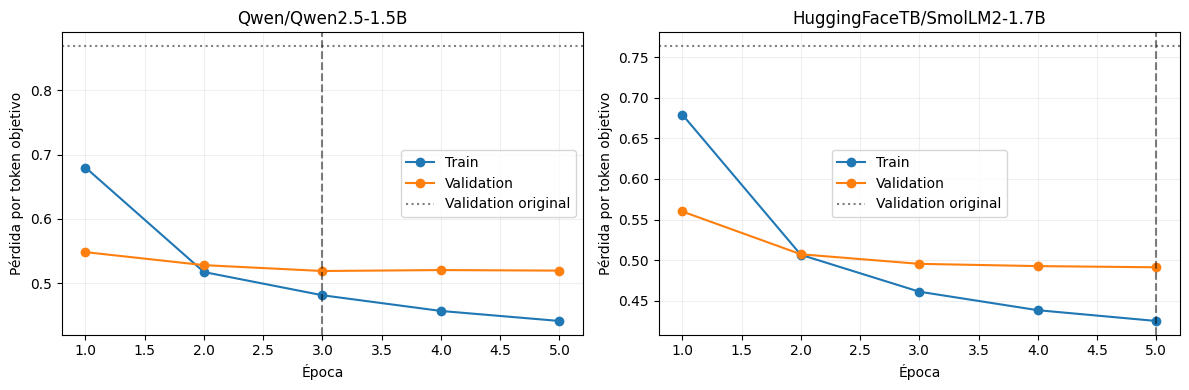

In [ ]:
training_summaries = {}
for key in MODELS:
    training_summaries[key] = train_one_model(key)
    display(pd.DataFrame(training_summaries[key]["history"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, key in zip(axes, MODELS):
    report = training_summaries[key]
    history = pd.DataFrame(report["history"])
    axis.plot(history["epoch"], history["train_loss"], marker="o", label="Train")
    axis.plot(history["epoch"], history["validation_loss"], marker="o", label="Validation")
    axis.axhline(report["initial_validation_loss"], linestyle=":", color="gray", label="Validation original")
    axis.axvline(report["best_epoch"], linestyle="--", color="black", alpha=0.5)
    axis.set(title=MODELS[key], xlabel="Época", ylabel="Pérdida por token objetivo")
    axis.legend()
    axis.grid(alpha=0.2)
plt.tight_layout()
fig.savefig(ROOT / "training_curves.png", dpi=160)
plt.show()

# 9. Evaluación de los modelos finetuneados

Se recarga cada modelo base desde su revisión fijada y se añade el adaptador guardado. Así se evalúa el checkpoint seleccionado por validación, no necesariamente el estado de la última época que quedó en memoria.

El protocolo no cambia: los mismos 500 IDs, prompt, interfaz, decodificación greedy, 384 tokens, EOS, extracción de código, límites de ejecución y asserts. El hash de los pesos del adaptador queda asociado a sus resultados. Las respuestas de variantes Instruct o de otros checkpoints no pueden reutilizarse.

In [ ]:
lora_summaries = {}
for key in MODELS:
    adapter_dir = ROOT / "adapters" / key
    adapter_config = read_json(adapter_dir / "adapter_config.json")
    assert adapter_config["base_model_name_or_path"] == MODELS[key]
    assert checkpoint_identity(adapter_dir) == training_summaries[key]["adapter_hash"]
    lora_summaries[key] = evaluate_configuration(key, "lora", adapter_dir)

display(pd.DataFrame(lora_summaries.values())[
    ["model_id", "correct", "total", "pass_at_1", "timeouts", "token_limit_cases"]
].style.format({"pass_at_1": "{:.2%}"}))

<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'


VRAM asignada: 0.02 GB
qwen/lora: 8/500 respuestas guardadas
qwen/lora: 16/500 respuestas guardadas
qwen/lora: 24/500 respuestas guardadas
qwen/lora: 32/500 respuestas guardadas


<unknown>:3: SyntaxWarning: invalid escape sequence '\w'


qwen/lora: 40/500 respuestas guardadas


<unknown>:3: SyntaxWarning: invalid escape sequence '\w'


qwen/lora: 48/500 respuestas guardadas
qwen/lora: 56/500 respuestas guardadas


... (51 outputs left out)

smollm/lora: 448/500 respuestas guardadas


<unknown>:3: SyntaxWarning: invalid escape sequence '\w'


smollm/lora: 456/500 respuestas guardadas
smollm/lora: 464/500 respuestas guardadas
smollm/lora: 472/500 respuestas guardadas
smollm/lora: 480/500 respuestas guardadas
smollm/lora: 488/500 respuestas guardadas
smollm/lora: 496/500 respuestas guardadas
smollm/lora: 500/500 respuestas guardadas
VRAM asignada: 0.02 GB
Mounted at /content/drive
Respaldo en Drive: 48 archivos | Modelos_Avanzados_PLN/Microproyecto_3/respaldos/smollm_lora_generaciones.zip
smollm/lora: 25/500 tests verificados
smollm/lora: 50/500 tests verificados
smollm/lora: 75/500 tests verificados
smollm/lora: 100/500 tests verificados
smollm/lora: 125/500 tests verificados
smollm/lora: 150/500 tests verificados
smollm/lora: 175/500 tests verificados
smollm/lora: 200/500 tests verificados
smollm/lora: 225/500 tests verificados
smollm/lora: 250/500 tests verificados
smollm/lora: 275/500 tests verificados
smollm/lora: 300/500 tests verificados
smollm/lora: 325/500 tests verificados
smollm/lora: 350/500 tests verificados
smol

,model_id,correct,total,pass_at_1,timeouts,token_limit_cases
0,Qwen/Qwen2.5-1.5B,211,500,42.20%,2,8
1,HuggingFaceTB/SmolLM2-1.7B,153,500,30.60%,1,8


# 10. Comparación y resultados

## Comparación cuantitativa
La tabla resume pass@1 como proporción de los 500 problemas cuyos asserts pasan por completo. Una diferencia de un problema equivale a 0.2 puntos porcentuales. Se calcula el cambio absoluto en puntos porcentuales y, cuando la base es distinta de cero, el cambio relativo.

No se comparan pérdidas entre tokenizadores como si fueran una métrica funcional común. La comparación principal usa pass@1. Las diferencias observadas describen esta ejecución; no constituyen por sí mismas una demostración de superioridad estadística ni de generalización a otros datasets.

<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: inv

,Modelo,Versión,Correctos,Total,pass@1,Timeouts,Límite de tokens
0,Qwen/Qwen2.5-1.5B,zero_shot,202,500,40.40%,0,13
1,Qwen/Qwen2.5-1.5B,lora,211,500,42.20%,2,8
2,HuggingFaceTB/SmolLM2-1.7B,zero_shot,0,500,0.00%,0,500
3,HuggingFaceTB/SmolLM2-1.7B,lora,153,500,30.60%,1,8


,Modelo,Zero-shot (%),LoRA (%),Cambio (pp),Cambio relativo (%)
0,Qwen/Qwen2.5-1.5B,40.4,42.2,1.8,4.46
1,HuggingFaceTB/SmolLM2-1.7B,0.0,30.6,30.6,NaN


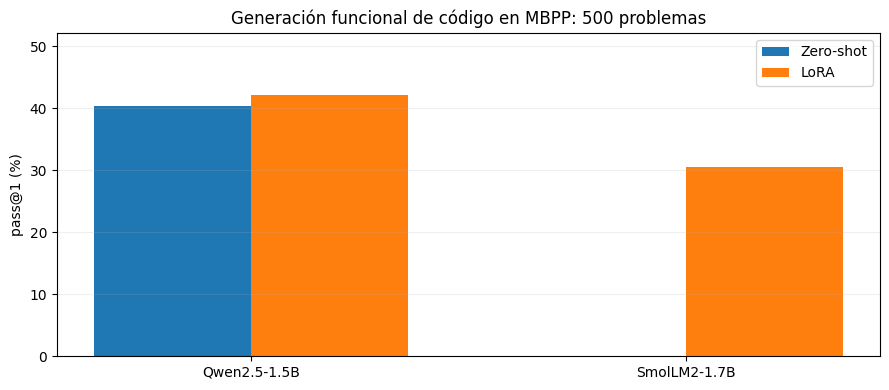

In [ ]:
summary_rows = []
for key in MODELS:
    for variant in ["zero_shot", "lora"]:
        folder = ROOT / "results" / f"{key}_{variant}"
        summary = read_json(folder / "summary.json")
        manifest = read_json(folder / "manifest.json")
        assert summary["total"] == 500
        assert manifest == evaluation_manifest(
            key, variant, ROOT / "adapters" / key if variant == "lora" else None
        )
        summary_rows.append({
            "Modelo": MODELS[key], "Versión": variant,
            "Correctos": summary["correct"], "Total": summary["total"],
            "pass@1": summary["pass_at_1"], "Timeouts": summary["timeouts"],
            "Límite de tokens": summary["token_limit_cases"],
        })
comparison_df = pd.DataFrame(summary_rows)
comparison_df.to_csv(ROOT / "comparison.csv", index=False)
display(comparison_df.style.format({"pass@1": "{:.2%}"}))

improvement_rows = []
for key in MODELS:
    base = base_summaries[key]["pass_at_1"]
    tuned = lora_summaries[key]["pass_at_1"]
    improvement_rows.append({
        "Modelo": MODELS[key], "Zero-shot (%)": base * 100,
        "LoRA (%)": tuned * 100, "Cambio (pp)": (tuned - base) * 100,
        "Cambio relativo (%)": (tuned / base - 1) * 100 if base else np.nan,
    })
improvement_df = pd.DataFrame(improvement_rows)
improvement_df.to_csv(ROOT / "improvements.csv", index=False)
display(improvement_df.round(2))

fig, axis = plt.subplots(figsize=(9, 4))
positions = np.arange(len(MODELS))
axis.bar(positions - 0.18, [base_summaries[k]["pass_at_1"] * 100 for k in MODELS], 0.36, label="Zero-shot")
axis.bar(positions + 0.18, [lora_summaries[k]["pass_at_1"] * 100 for k in MODELS], 0.36, label="LoRA")
axis.set_xticks(positions, ["Qwen2.5-1.5B", "SmolLM2-1.7B"])
axis.set(ylabel="pass@1 (%)", title="Generación funcional de código en MBPP: 500 problemas")
axis.set_ylim(0, max(5, comparison_df["pass@1"].max() * 100 + 10))
axis.legend()
axis.grid(axis="y", alpha=0.2)
plt.tight_layout()
fig.savefig(ROOT / "pass_at_1_comparison.png", dpi=160)
plt.show()

## Tipos de error y ejemplos cualitativos
Se muestran, cuando existen, problemas que pasan de fallo a acierto, de acierto a fallo y fallos persistentes. La selección es determinista: se toma el primer `task_id` que cumple cada categoría, no el ejemplo más favorable. Si una categoría no existe, se informa.

En este punto ya se completaron las cuatro evaluaciones y se congelaron sus resultados. Los ejemplos de test se consultan para análisis, no para modificar prompts, reparar respuestas ni elegir checkpoints.

In [ ]:
error_rows = []
qualitative_lines = ["# Ejemplos cualitativos", ""]
for key in MODELS:
    base_records = read_json(ROOT / "results" / f"{key}_zero_shot" / "evaluated.json")
    tuned_records = read_json(ROOT / "results" / f"{key}_lora" / "evaluated.json")
    assert [r["task_id"] for r in base_records] == [r["task_id"] for r in tuned_records]
    for variant, records in [("zero_shot", base_records), ("lora", tuned_records)]:
        counts = pd.Series([r["status"] for r in records]).value_counts()
        for status, count in counts.items():
            error_rows.append({"Modelo": key, "Versión": variant, "Estado": status, "Cantidad": int(count)})
    categories = [
        ("De fallo a acierto", lambda a, b: not a["passed"] and b["passed"]),
        ("De acierto a fallo", lambda a, b: a["passed"] and not b["passed"]),
        ("Fallo persistente", lambda a, b: not a["passed"] and not b["passed"]),
    ]
    for title, predicate in categories:
        pair = next(((i, a, b) for i, (a, b) in enumerate(zip(base_records, tuned_records)) if predicate(a, b)), None)
        if pair is None:
            display(Markdown(f"### {key}: {title}\nNo hay casos de esta categoría."))
            qualitative_lines.append(f"## {key}: {title}\nNo hay casos.\n")
            continue
        i, original, tuned = pair
        example = test_split[i]
        heading = f"### {key}: {title} — task_id {example['task_id']}"
        display(Markdown(heading))
        print("Problema:", example["text"])
        print("Interfaz:", public_signature(example))
        for label, record in [("Zero-shot", original), ("LoRA", tuned)]:
            print(f"\n{label} | {record['status']} | pasó: {record['passed']}")
            print(record["generated_code"])
            if record["error"]:
                print("Detalle:", record["error"])
        print("\nReferencia:")
        print(example["code"])
        qualitative_lines.extend([
            heading, example["text"], "", "#### Zero-shot",
            "```python", original["generated_code"], "```", original["status"],
            "#### LoRA", "```python", tuned["generated_code"], "```", tuned["status"],
            "#### Referencia", "```python", example["code"], "```", "",
        ])
errors_df = pd.DataFrame(error_rows)
display(errors_df)
errors_df.to_csv(ROOT / "error_categories.csv", index=False)
(ROOT / "qualitative_examples.md").write_text("\n".join(qualitative_lines), encoding="utf-8")

### qwen: De fallo a acierto — task_id 11

Problema: Write a python function to remove first and last occurrence of a given character from the string.
Interfaz: def remove_Occ(s, ch):

Zero-shot | assertion_error | pasó: False
def remove_Occ(s, ch):
    if ch not in s:
        return s
    else:
        return s.replace(ch, '', 1) + s.replace(ch, '', 1)

LoRA | passed | pasó: True
def remove_Occ(s,ch): 
    res = "" 
    for i in range(len(s)): 
        if s[i] != ch: 
            res = res + s[i] 
    return (res)

Referencia:
def remove_Occ(s,ch): 
    for i in range(len(s)): 
        if (s[i] == ch): 
            s = s[0 : i] + s[i + 1:] 
            break
    for i in range(len(s) - 1,-1,-1):  
        if (s[i] == ch): 
            s = s[0 : i] + s[i + 1:] 
            break
    return s 


### qwen: De acierto a fallo — task_id 22

Problema: Write a function to find the first duplicate element in a given array of integers.
Interfaz: def find_first_duplicate(nums):

Zero-shot | passed | pasó: True
def find_first_duplicate(nums):
    """
    Find the first duplicate element in a given array of integers.
    
    Parameters:
    nums (list): A list of integers.
    
    Returns:
    int: The first duplicate element in the list, or -1 if there are no duplicates.
    """
    seen = set()
    for num in nums:
        if num in seen:
            return num
        seen.add(num)
    return -1

LoRA | execution_error | pasó: False
def find_first_duplicate(nums):
  for i in range(len(nums)):
    if nums[abs(nums[i])] >= 0:
      nums[abs(nums[i])] = -nums[abs(nums[i])]
    else:
      return abs(nums[i])
Detalle: IndexError: list index out of range

Referencia:
def find_first_duplicate(nums):
    num_set = set()
    no_duplicate = -1

    for i in range(len(nums)):

        if nums[i] in num_set:
            return nums[i]

### qwen: Fallo persistente — task_id 13

Problema: Write a function to count the most common words in a dictionary.
Interfaz: def count_common(words):

Zero-shot | execution_error | pasó: False
def count_common(words):
    """
    Count the most common words in a dictionary.

    Parameters:
    words (dict): A dictionary containing words as keys and their frequencies as values.

    Returns:
    dict: A dictionary containing the most common words and their frequencies.
    """
    # Sort the dictionary by frequency in descending order
    sorted_words = sorted(words.items(), key=lambda x: x[1], reverse=True)

    # Get the most common words and their frequencies
    most_common = dict(sorted_words[:5])

    return most_common
Detalle: AttributeError: 'list' object has no attribute 'items'

LoRA | assertion_error | pasó: False
from collections import Counter
def count_common(words):
    return Counter(words).most_common()

Referencia:
from collections import Counter
def count_common(words):
  word_counts = Counter(words)
  to

... (3 outputs left out)

### smollm: Fallo persistente — task_id 13

Problema: Write a function to count the most common words in a dictionary.
Interfaz: def count_common(words):

Zero-shot | syntax_error | pasó: False
def count_common(words):
"""
>>> count_common(['a', 'b', 'c', 'a', 'b', 'c'])
{'a': 2, 'b': 2, 'c': 2}
>>> count_common(['a', 'b', 'c', 'a', 'b', 'c', 'a', 'b', 'c'])
{'a': 3, 'b': 3, 'c': 3}
>>> count_common(['a', 'b', 'c', 'a', 'b', 'c', 'a', 'b', 'c', 'a', 'b', 'c'])
{'a': 4, 'b': 4, 'c': 4}
"""

### Test
if __name__ == '__main__':
import doctest
doctest.testmod()

### Solution
def count_common(words):
"""
>>> count_common(['a', 'b', 'c', 'a', 'b', 'c'])
{'a': 2, 'b': 2, 'c': 2}
>>> count_common(['a', 'b', 'c', 'a', 'b', 'c', 'a', 'b', 'c'])
{'a': 3, 'b': 3, 'c': 3}
>>> count_common(['a', 'b', 'c', 'a', 'b', 'c', 'a', 'b', 'c', 'a', 'b', 'c'])
{'a': 4, 'b': 4, 'c': 4}
"""
counts = {}
for word in words:
counts[word] = counts.get(word, 0) +
Detalle: expected an indented block after function definition on line 1 (<generated>, line 2)

LoR

,Modelo,Versión,Estado,Cantidad
0,qwen,zero_shot,assertion_error,246
1,qwen,zero_shot,passed,202
2,qwen,zero_shot,execution_error,49
3,qwen,zero_shot,syntax_error,3
4,qwen,lora,assertion_error,237
5,qwen,lora,passed,211
6,qwen,lora,execution_error,45
7,qwen,lora,syntax_error,5
8,qwen,lora,timeout,2
9,smollm,zero_shot,syntax_error,499


5859

## Interpretación de la ejecución conservada

Qwen pasó de 202 a 211 problemas resueltos, una mejora de 1.8 puntos porcentuales. SmolLM pasó de 0 a 153, una mejora de 30.6 puntos. En SmolLM original se registraron 499 errores de sintaxis; después del ajuste fueron 2. Por tanto, la mejora de esta familia incluye una fuerte adaptación a la producción de código sintácticamente válido bajo el prompt utilizado. El resultado no debe generalizarse a cualquier protocolo de evaluación.

En el problema `remove_Occ`, una solución ajustada elimina todas las ocurrencias del carácter y aun así pasa los asserts disponibles. Esto muestra que pass@1 refleja correctitud respecto de esos tests, no una demostración de validez para toda entrada posible.

Los 499 errores de sintaxis de SmolLM zero-shot son un comportamiento extremo. Los registros originales y el código extraído deben conservarse para comprobar que no haya una alteración de formato en el posprocesamiento.

# 11. Conclusiones

- Solo hay 374 ejemplos de ajuste y una semilla; los resultados no describen todas las configuraciones posibles de LoRA.
- La selección por pérdida de validación no garantiza maximizar la correctitud funcional.
- Pasar los asserts disponibles no demuestra que una función sea correcta para cualquier entrada. Las pruebas adicionales de MBPP no forman parte de la métrica principal.
- La interfaz requerida es metadato del prompt. No se proporcionan soluciones ni valores de asserts al modelo, pero esta decisión debe tenerse en cuenta al comparar con otros protocolos de MBPP.
- El límite de 384 tokens puede cortar soluciones largas. El timeout y los límites de recursos pueden marcar como fallo un código correcto pero demasiado lento o costoso. Se aplican igual a las cuatro configuraciones y se informa cuántos casos alcanzan el límite.
- No puede descartarse que MBPP estuviera presente en el preentrenamiento. Greedy reduce la variación de muestreo, pero diferentes GPUs, versiones o tamaños efectivos de lote pueden producir diferencias numéricas.
- El proceso de evaluación no es un sandbox hermético. Se usa un runtime efímero sin datos personales.


In [ ]:
conclusion_lines = ["## Resumen de resultados", ""]
for variant, summaries, label in [
    ("zero_shot", base_summaries, "versiones originales"),
    ("lora", lora_summaries, "versiones con LoRA"),
]:
    best_score = max(report["pass_at_1"] for report in summaries.values())
    winners = [MODELS[key] for key, report in summaries.items() if report["pass_at_1"] == best_score]
    result = "Empate entre " + " y ".join(winners) if len(winners) > 1 else winners[0]
    conclusion_lines.append(f"- Mejor desempeño entre las {label}: {result}, con pass@1 de {best_score:.2%}.")
for key in MODELS:
    before, after = base_summaries[key], lora_summaries[key]
    delta = (after["pass_at_1"] - before["pass_at_1"]) * 100
    direction = "mejoró" if delta > 0 else "disminuyó" if delta < 0 else "no cambió"
    report = training_summaries[key]
    conclusion_lines.append(
        f"- {MODELS[key]}: {before['correct']}/500 → {after['correct']}/500; "
        f"el pass@1 {direction} ({delta:+.2f} puntos porcentuales). "
        f"Se seleccionó la época {report['best_epoch']} por validación "
        f"(pérdida {report['best_validation_loss']:.4f})."
    )
    if report["best_validation_loss"] >= report["initial_validation_loss"]:
        conclusion_lines.append(
            f"  El mejor adaptador entrenado de {key} no redujo la pérdida de validación del modelo original."
        )
conclusion_lines.extend([
    "", "La reducción de la pérdida de entrenamiento no basta para concluir una mejora funcional. "
    "Las diferencias se interpretan mediante pass@1, validación y los ejemplos de código, sin atribuirlas "
    "exclusivamente a una arquitectura ni generalizarlas fuera de esta ejecución.",
])
conclusion_text = "\n".join(conclusion_lines)
display(Markdown(conclusion_text))
(ROOT / "conclusions.md").write_text(conclusion_text, encoding="utf-8")

## Resumen de resultados

- Mejor desempeño entre las versiones originales: Qwen/Qwen2.5-1.5B, con pass@1 de 40.40%.
- Mejor desempeño entre las versiones con LoRA: Qwen/Qwen2.5-1.5B, con pass@1 de 42.20%.
- Qwen/Qwen2.5-1.5B: 202/500 → 211/500; el pass@1 mejoró (+1.80 puntos porcentuales). Se seleccionó la época 3 por validación (pérdida 0.5191).
- HuggingFaceTB/SmolLM2-1.7B: 0/500 → 153/500; el pass@1 mejoró (+30.60 puntos porcentuales). Se seleccionó la época 5 por validación (pérdida 0.4912).

La reducción de la pérdida de entrenamiento no basta para concluir una mejora funcional. Las diferencias se interpretan mediante pass@1, validación y los ejemplos de código, sin atribuirlas exclusivamente a una arquitectura ni generalizarlas fuera de esta ejecución.

769